# 07 · Networks and multi-model simulations: water that leaves the grid and comes back

In tutorials 01 to 06 every external term was an end point: water entering through recharge or a river started there, and water leaving through a drain or a well was gone. Real models are less tidy. A drain may hand its water to a stream through the water mover (MVR), the stream may lose that water back to the aquifer a kilometre away, and a pumping well there may take it. A multi-aquifer well (MAW) takes water from one layer and loses part of it into another through its borehole. And a large model may be split into several models joined by exchanges.

In each case water passes through something that is not a model cell. If the trace stops at the cell boundary, the route is cut: water handed to the stream looks lost, and water leaking from the stream looks like a new source with no history. `gwsource` can instead read these features as **nodes** of the same graph, so the full-mixing trace follows the water through them.

This tutorial covers three such cases:

1. **Stream and mover** (SFR + MVR): drains feed a stream that leaks to the aquifer near a well. First a trace on the cells alone, then with one node per stream reach and the mover transfers as edges, following drain → MVR → stream → aquifer → well.
2. **A multi-aquifer well** (MAW) screened in three layers, which moves water from layer 1 to layer 3 through its borehole.
3. **A split model**: the quickstart model cut into three models joined by GWF-GWF exchanges gives the same answer as the single model.

It closes with the MODFLOW 6 options these features need and the current limitations.

**Runtime:** about 3 seconds (the last code cell prints the measured time). **Prerequisites:** tutorial 01 (fraction through, volume from); the [tutorial README](../README.md) for setup.

## Settings

All settings live in this first cell. Later cells use only these names and what earlier cells return. Workspaces go to `tutorials/_work/07_networks_multimodel/` (git-ignored, recreated on every run). The shared builders are in [`herebedragons.py`](../herebedragons.py). A route diagram, a cross-section and two small tables specific to this tutorial are in [`helpers.py`](helpers.py), next to this notebook.

In [1]:
import sys
import time
from pathlib import Path

import flopy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # tutorials/ holds the shared helpers
sys.path.insert(0, str(Path.cwd()))  # this folder holds helpers.py
import herebedragons as hbd  # noqa: E402
import helpers  # noqa: E402  (this tutorial's route diagram, cross-section and tables)

import gwsource as gs  # noqa: E402

T_START = time.perf_counter()  # for the runtime printed at the end
WORK = hbd.work_dir("07_networks_multimodel", clean=True)  # tutorials/_work/... (git-ignored)
MF6 = hbd.mf6_exe()  # <repo>/bin/mf6
WELL = "supply_well"  # boundname of the supply well traced in every part
SPLIT_ROW, SPLIT_COL = 20, 20  # the split: west half, north-east and south-east quarters

plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.0, 5.5)})
print(f"gwsource {gs.__version__}, FloPy {flopy.__version__}")

gwsource 0.0.1, FloPy 3.12.0.dev0


## 1. A stream fed by drains

`hbd.build_stream_mover` keeps the tutorial plan (2 km × 2 km, 50 m cells, recharge, constant-head west edge, supply well in row 21, column 29) but replaces the river with a **stream** (SFR), one reach per row down column 31, flowing north to south:

- 300 m³/d enters the first (northern) reach from upstream;
- the stream bed falls 8 cm per reach, so the upper reaches sit above the water table and *lose* water to the aquifer, and the lower reaches *gain*;
- two **drains** west of the stream (rows 9 and 23, column 15) hand their outflow to the first reach through the **water mover** (MVR): 80 % of `drain_a`'s water and all of `drain_b`'s. The rest of `drain_a`'s water leaves the model.

So drained groundwater is carried to the head of the stream, part of it leaks back into the aquifer, and the supply well may pump it. The builder saves the SFR and MVR budgets to their own files (`BUDGET FILEOUT`), which section 3 needs. Rows and columns are counted from 1, from the north-west corner, as in tutorials 01 to 03.

In [2]:
stream = hbd.build_stream_mover(WORK / "stream", MF6)
cells_only = gs.read_step(stream.ws, boundnames=True)

LABELS = {
    "WEL": "supply well", "DRN": "drains (leaving the model)", "DRN:DRN-TO-MVR": "drains (to the mover)",
    "RCH": "recharge", "CHD": "west edge", "SFR": "stream leakage / seepage",
}
rows = {}
for index, name in enumerate(cells_only.package_names):
    q = cells_only.term_flow[cells_only.term_package == index]
    rows[LABELS.get(name, name)] = {"in (m3/d)": q[q > 0].sum(), "out (m3/d)": 0.0 - q[q < 0].sum()}
display(pd.DataFrame(rows).T.round(1))
print(f"the two drain records together: {rows[LABELS['DRN']]['out (m3/d)'] + rows[LABELS['DRN:DRN-TO-MVR']]['out (m3/d)']:.1f} m3/d")

,in (m3/d),out (m3/d)
supply well,0.0,800.0
drains (leaving the model),0.0,49.3
drains (to the mover),0.0,436.4
recharge,1950.0,0.0
west edge,0.0,1177.7
stream leakage / seepage,641.7,128.3


the two drain records together: 485.6 m3/d


This is the budget of the aquifer cells. Recharge (1950 m³/d) and stream leakage (about 640 m³/d) bring water in. Without a river to drain it, the water table stands above 10 m over most of the model, so the west edge is an *outlet* in this variant. The drains take about 485 m³/d, of which about 435 m³/d is handed to the mover: MF6 writes two records per drain, `DRN` for the part that leaves the model and `DRN-TO-MVR` for the moved part.

The heads show the stream's effect: a mound under the losing upper reaches in the north, and the cone of depression of the supply well next to the stream.

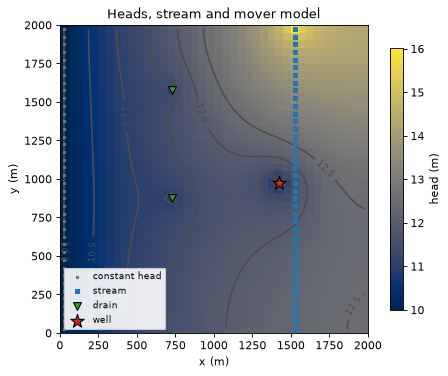

In [3]:
heads = flopy.utils.HeadFile(str(stream.head_file)).get_data().ravel()
ax = hbd.plot_cells(stream.grb_file, cells_only, heads, cmap="cividis", title="Heads, stream and mover model",
                    label="head (m)")
hbd.add_contours(ax, stream.grb_file, cells_only, heads, np.arange(8.0, 13.0, 0.5), colors="0.3", fmt="%.1f")
plt.show()

## 2. Trace on the cells alone: the stream is an opaque source

`gs.read_step` reads the aquifer cells only (as in tutorials 01 to 06). Every SFR record in the aquifer budget becomes an external term of its cell: positive (stream → aquifer) is a **source**, negative (aquifer → stream) a **sink**. The `DRN-TO-MVR` records are sinks too. The route drain → mover → stream → aquifer is cut in two places.

In [4]:
back_off = gs.backward(cells_only, {WELL: gs.select(cells_only, boundnames=[WELL])})
F_off = back_off.fraction_through[WELL]
display(hbd.volume_from_table(back_off, WELL).round({"volume_from": 1, "share": 3}))
drain_nodes = stream.info["drain_nodes"]  # {boundname: cell}
print("fraction through in the drain cells:", {b: round(float(F_off[n]), 3) for b, n in drain_nodes.items()})

,volume_from,share
source,,
RCH,544.8,0.681
SFR,255.2,0.319


fraction through in the drain cells: {'drain_a': 0.0, 'drain_b': 0.0}


On the cells alone, about a third of the well's water (about 255 m³/d) is "SFR": it leaked from the stream, and the trace cannot say where the stream got it. The drain cells have $F = 0$: their water leaves through the drain and, as far as this graph knows, is gone. Both statements describe the graph. Neither describes where the water goes.

## 3. Open the simulation with package nodes

`gs.open_simulation(ws, package_nodes=("SFR",))` reads the same model as one **global graph**: first the model cells, then one node per stream reach. The graph is built from three budget files:

- **aquifer budget**: the cell-to-cell flows and the external terms, as before. The aquifer-side SFR records are dropped and replaced by
- **SFR budget** (`BUDGET FILEOUT` in SFR): one edge per reach–cell exchange (the `GWF` record) and per reach–reach connection (`FLOW-JA-FACE`); the reach's other records (`EXT-INFLOW`, `EXT-OUTFLOW`, rainfall, evaporation, runoff) become its source and sink terms, named `SFR:<record>`;
- **MVR budget** (`BUDGET FILEOUT` in MVR): each transfer from a provider (here a drain) to a receiver with nodes (here reach 1) becomes an edge from the drain cell to the reach, and the provider's `DRN-TO-MVR` sink is reduced by the same amount.

Package nodes are chosen when the step is read, not in `TraceConfig`: the graph changes, and every trace, metric and diagnostic then works on the larger graph unchanged.

In [5]:
reader = gs.open_simulation(stream.ws, package_nodes=("SFR",), boundnames=True)
network = reader.read((0, 0))
for block in network.blocks:
    print(f"{block.label:8s} {block.kind:8s} nodes {block.offset}..{block.offset + block.n - 1}")
print("terms:", ", ".join(network.package_names))
print(f"mover transfers routed as edges: {network.notes['mover_routed']:.1f} m3/d")

reaches = network.block("SFR").nodes
exchange = helpers.reach_exchange(network, "SFR")
print(f"stream -> aquifer {exchange['to_cells'].sum():.1f} m3/d, aquifer -> stream (incl. mover) "
      f"{exchange['from_cells'].sum():.1f} m3/d")
display(exchange.head(6).round(1))

stream   model    nodes 0..1599
stream/SFR package  nodes 1600..1639
terms: WEL, DRN, DRN:DRN-TO-MVR, RCH, CHD, SFR:RAINFALL, SFR:EVAPORATION, SFR:RUNOFF, SFR:EXT-INFLOW, SFR:EXT-OUTFLOW, SFR:STORAGE, SFR:FROM-MVR, SFR:TO-MVR
mover transfers routed as edges: 436.4 m3/d
stream -> aquifer 641.7 m3/d, aquifer -> stream (incl. mover) 564.7 m3/d


,from_cells,to_cells
id,,
1,436.4,562.4
2,46.7,0.0
3,0.0,25.3
4,0.0,3.8
5,0.0,5.6
6,0.0,3.6


The 1600 cells keep their node numbers. The 40 reaches are nodes 1600 to 1639. The table lists, for the first reaches, the water each receives from cells (seepage, and for reach 1 the mover edges from the two drain cells) and loses to cells. Reach 1 takes in the 436 m³/d from the drains on top of the 300 m³/d upstream inflow and loses about 560 m³/d into the aquifer: most of the drained water goes straight back into the ground, a kilometre north-east of the drains.

### Trace again

Selection works as before: the well by boundname, a reach term with `package="SFR", term="EXT-INFLOW"`.

In [6]:
back_on = gs.backward(network, {WELL: gs.select(network, boundnames=[WELL])})
F_on = back_on.fraction_through[WELL]
n_cells = network.block(stream.name).n  # the model's cells come first in the global numbering

drains = pd.DataFrame(
    {"F, cells only": [F_off[n] for n in drain_nodes.values()],
     "F, with SFR nodes": [F_on[n] for n in drain_nodes.values()]},
    index=pd.Index(list(drain_nodes), name="drain cell"),
)
display(drains.round(3))
print(f"F of reach 1: {F_on[reaches[0]]:.3f}; solver: {back_on.solver_used[0]}, "
      f"{len(back_on.cycles)} flow loop(s), the largest through {max(c.cells.size for c in back_on.cycles)} nodes")

,"F, cells only","F, with SFR nodes"
drain cell,,
drain_a,0.0,0.345
drain_b,0.0,0.431


F of reach 1: 0.431; solver: block, 1 flow loop(s), the largest through 711 nodes


The drain cells now have $F \approx 0.35$ and $0.43$. Their water goes to the mover, the mover sends it to reach 1, and 43 % of what passes through reach 1 ends up in the well. `drain_b` moves all its water, so its $F$ equals that of reach 1. `drain_a` moves 80 %, so its $F$ is $0.8 \times 0.43 = 0.35$.

The graph now also has a **flow loop**: part of the water that reach 1 loses to the aquifer flows west to `drain_a` and is moved back to reach 1. On the cells alone the graph had no flow loop. `gwsource` solves graphs with flow loops exactly (here with the block-triangular solver, as in tutorial 04), so nothing special is needed.

The maps below compare the two traces. The right panel shows the $F$ of each reach, from reach 1 in the north to reach 40 in the south.

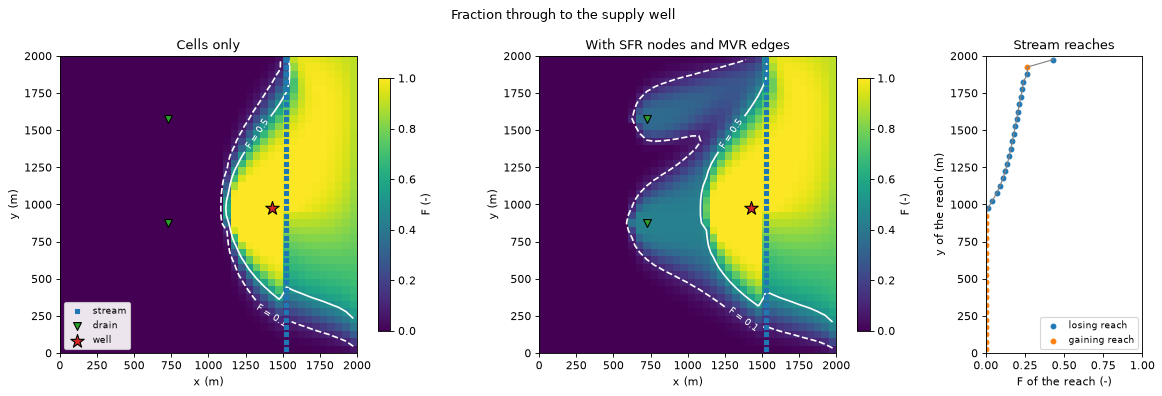

F > 0 in every reach from 1 to 21: True; F of reach 1 0.43, of reach 21 0.014
largest F of reaches 22 to 40: 0.0
gaining reaches: [2, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]


In [7]:
points = gs.export.package_points(network)  # {reach node: (x, y) of the cell it exchanges with}
xy = np.array([points[int(n)] for n in reaches])
losing = exchange["to_cells"].to_numpy() > exchange["from_cells"].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(15.0, 5.0), gridspec_kw={"width_ratios": [1.0, 1.0, 0.38]})
for ax, F, title in ((axes[0], F_off[:n_cells], "Cells only"), (axes[1], F_on[:n_cells], "With SFR nodes and MVR edges")):
    hbd.plot_cells(stream.grb_file, cells_only, F, ax=ax, cmap="viridis", vmin=0.0, vmax=1.0, title=title,
                   label="F (-)", overlay=False)
    hbd.add_contours(ax, stream.grb_file, cells_only, F, (0.1, 0.5), colors="w", linestyles=["--", "-"])
    hbd.overlay_features(ax, stream.grb_file, cells_only, packages=("SFR", "DRN", "WEL"), legend=ax is axes[0])
axes[2].plot(F_on[reaches], xy[:, 1], color="0.5", lw=1.0)
axes[2].scatter(F_on[reaches][losing], xy[losing, 1], color="tab:blue", s=18, label="losing reach")
axes[2].scatter(F_on[reaches][~losing], xy[~losing, 1], color="tab:orange", s=18, label="gaining reach")
axes[2].set_ylim(0.0, stream.spec.ly)
axes[2].set_xlim(0.0, 1.0)
axes[2].set_xlabel("F of the reach (-)")
axes[2].set_ylabel("y of the reach (m)")
axes[2].set_title("Stream reaches")
axes[2].legend(fontsize=8, loc="lower right")
fig.suptitle("Fraction through to the supply well")
fig.tight_layout()
plt.show()

F_reach = pd.Series(F_on[reaches], index=pd.RangeIndex(1, len(reaches) + 1, name="reach"))
last_feeding = int(F_reach[F_reach > 0.0].index.max())  # the last reach that passes water to the well
print(f"F > 0 in every reach from 1 to {last_feeding}: {bool((F_reach.loc[:last_feeding] > 0.0).all())}; "
      f"F of reach 1 {F_reach.loc[1]:.2f}, of reach {last_feeding} {F_reach.loc[last_feeding]:.3f}")
print(f"largest F of reaches {last_feeding + 1} to {F_reach.index[-1]}: {F_reach.loc[last_feeding + 1:].max():.1f}")
print("gaining reaches:", list(F_reach.index[~losing]))

Left, the capture zone stops at the stream, whose leaking reaches near the well act as sources, and it never reaches the drains. Middle, the zone also covers a lobe around each drain: the drained area that feeds the mover. Right, every reach from 1 to 21 passes part of its water to the well. $F$ falls from 0.43 at reach 1 to 0.014 at reach 21. It is 0 from reach 22 to reach 40. These lower reaches all gain water from the aquifer and carry it to the outlet. Reach 2 gains water as well, but it passes that water on to the losing reaches below it. Close to the well the two maps agree, because the flows are the same; only the bookkeeping at the stream and the drains has changed.

### The route, by numbers

How much of the well's water came through the drains? Each mover edge carries $q$ from a drain cell to reach 1. The part that ends in the well is $q \times F_\text{reach 1}$. The volume through reach 1 ($F \times$ outflow) is everything the well receives through the head of the stream.

In [8]:
mover = helpers.edges_between(network, list(drain_nodes.values()), reaches)
mover["drain"] = [b for n in mover["src"] for b, node in drain_nodes.items() if node == n]
mover["F of receiving reach"] = F_on[mover["dst"]]
mover["to well (m3/d)"] = mover["q"] * mover["F of receiving reach"]
display(mover.set_index("drain")[["q", "F of receiving reach", "to well (m3/d)"]].round(3))

via_mover = float(mover["to well (m3/d)"].sum())
inflow_reach1 = float(network.term_flow[gs.select(network, package="SFR", term="EXT-INFLOW").terms].sum())
leak_reach1 = float(exchange.loc[1, "to_cells"])
through_reach1 = float(back_on.volume_through[WELL][reaches[0]])
print(f"well water that passed through reach 1:  {through_reach1:6.1f} m3/d")
print(f"  of which came through the mover:       {via_mover:6.1f} m3/d")
print(f"  of which is upstream stream inflow:    {through_reach1 - via_mover:6.1f} m3/d")

,q,F of receiving reach,to well (m3/d)
drain,,,
drain_a,197.042,0.431,85.001
drain_b,239.345,0.431,103.250


well water that passed through reach 1:   317.7 m3/d
  of which came through the mover:        188.3 m3/d
  of which is upstream stream inflow:     129.4 m3/d


The diagram summarises the route. Boxes are nodes or groups of nodes, and $F$ is the fraction of each node's water that reaches the well. Arrows carry flows of the model (m³/d), except the last one: the 318 m³/d is the part of reach 1's water that ends in the well (its volume through).

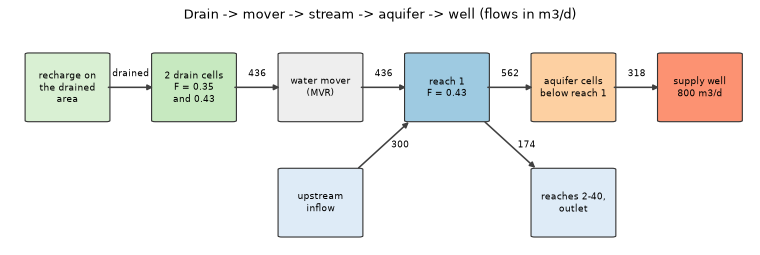

of the 318 m3/d the well receives through reach 1, 188 m3/d came through the mover


In [9]:
q_moved = float(mover["q"].sum())
F_drains = F_on[list(drain_nodes.values())]
boxes = {
    "rch": (0.08, 0.72, "recharge on\nthe drained\narea", "#d9f0d3"),
    "drn": (0.25, 0.72, f"2 drain cells\nF = {F_drains.min():.2f}\nand {F_drains.max():.2f}", "#c7e9c0"),
    "mvr": (0.42, 0.72, "water mover\n(MVR)", "#eeeeee"),
    "r1": (0.59, 0.72, f"reach 1\nF = {F_on[reaches[0]]:.2f}", "#9ecae1"),
    "aq": (0.76, 0.72, "aquifer cells\nbelow reach 1", "#fdd0a2"),
    "well": (0.93, 0.72, f"supply well\n{back_on.destination_inflow[WELL]:.0f} m3/d", "#fc9272"),
    "up": (0.42, 0.2, "upstream\ninflow", "#deebf7"),
    "down": (0.76, 0.2, "reaches 2-40,\noutlet", "#deebf7"),
}
arrows = [
    ("rch", "drn", "drained"),
    ("drn", "mvr", f"{q_moved:.0f}"),
    ("mvr", "r1", f"{q_moved:.0f}"),
    ("up", "r1", f"{inflow_reach1:.0f}"),
    ("r1", "aq", f"{leak_reach1:.0f}"),
    ("r1", "down", f"{exchange.loc[1, 'from_cells'] + inflow_reach1 - leak_reach1:.0f}"),
    ("aq", "well", f"{through_reach1:.0f}"),
]
fig, ax = plt.subplots(figsize=(12.0, 3.6))
helpers.route_diagram(ax, boxes, arrows, half=(0.052, 0.15),
                      title="Drain -> mover -> stream -> aquifer -> well (flows in m3/d)")
plt.show()
print(f"of the {through_reach1:.0f} m3/d the well receives through reach 1, {via_mover:.0f} m3/d came through the mover")

### The well's water by original source

With the stream as nodes, the stream is no longer a source: its water is traced back to where it entered the model. Two sources remain: recharge (part of it via the drains, the mover and the stream) and the stream's upstream inflow (`SFR:EXT-INFLOW`).

In [10]:
table = pd.concat(
    {"cells only": hbd.volume_from_table(back_off, WELL)["volume_from"],
     "with SFR nodes": hbd.volume_from_table(back_on, WELL)["volume_from"]}, axis=1
).fillna(0.0)
table.loc["  well water that passed through the mover"] = [0.0, via_mover]
table.loc["total"] = [back_off.destination_inflow[WELL], back_on.destination_inflow[WELL]]
display(table.round(1))

forward_on = gs.forward(network, {"recharge": gs.select(network, package="RCH"),
                                  "stream inflow": gs.select(network, package="SFR", term="EXT-INFLOW")})
origin = pd.DataFrame({g: forward_on.source_fraction[g][list(drain_nodes.values())] for g in forward_on.groups},
                      index=pd.Index(list(drain_nodes), name="water in drain cell, by origin"))
display(origin.round(3))
extra_recharge = table.loc["RCH", "with SFR nodes"] - table.loc["RCH", "cells only"]
print(f"extra recharge with SFR nodes: {extra_recharge:.1f} m3/d; well water through the mover: {via_mover:.1f} m3/d, "
      f"{via_mover / back_on.destination_inflow[WELL]:.1%} of the pumping")
for name, result, step in (("cells only", back_off, cells_only), ("with SFR nodes", back_on, network)):
    check = gs.diagnostics.backward_closure(step, result, WELL)
    print(f"closure, {name}: volume from {check.lhs:.7f} m3/d, residual term {check.residual_term:.1e} m3/d, "
          f"pumping {check.rhs:.1f} m3/d; relative error {check.relative_error:.1e}, "
          f"{abs(check.error_without_residual) / check.rhs:.1e} without the residual term")
    assert check.relative_error < 1e-8, check

,cells only,with SFR nodes
source,,
RCH,544.8,670.6
SFR,255.2,0.0
SFR:EXT-INFLOW,0.0,129.4
well water that passed through the mover,0.0,188.3
total,800.0,800.0


,recharge,stream inflow
"water in drain cell, by origin",,
drain_a,0.714,0.286
drain_b,0.928,0.072


extra recharge with SFR nodes: 125.8 m3/d; well water through the mover: 188.3 m3/d, 23.5% of the pumping
closure, cells only: volume from 800.0000000 m3/d, residual term 7.5e-09 m3/d, pumping 800.0 m3/d; relative error 1.4e-16, 9.4e-12 without the residual term
closure, with SFR nodes: volume from 800.0000004 m3/d, residual term 3.9e-07 m3/d, pumping 800.0 m3/d; relative error 0.0e+00, 4.9e-10 without the residual term


The 255 m³/d of "SFR" water splits into about 129 m³/d of upstream stream inflow and about 126 m³/d of recharge. The recharge share rises from 545 to 671 m³/d. The extra 126 m³/d is recharge that the cells-only trace lost at the drains or the stream. The closure check compares the volume from all sources with the pumping rate. The volume from also includes a small residual term: the flow model's own budget error in each cell, weighted by the cell's $F$. With that term counted, the check holds on both graphs to round-off. Without it, the relative errors are $9 \times 10^{-12}$ and $5 \times 10^{-10}$. The check is an identity of the trace. It shows that the bookkeeping adds up, not that the trace is right.

In all, 188 m³/d of the well's water (23.5 %) passed through the mover. That is more than the 126 m³/d of extra recharge because of the flow loop. A forward trace on the same network (second table) shows that about 30 % of the water in `drain_a`'s cell, and 7 % in `drain_b`'s, is upstream stream inflow that leaked from reach 1. That water passes through the mover and reach 1 a second time.

For a source-protection study, the drained area is part of the well's catchment. A cells-only trace would miss it.

## 4. A multi-aquifer well moves water between layers

`hbd.build_maw` uses the three-layer version of the aquifer (horizontal conductivity 10, 1 and 15 m/d from the top; vertical conductivity 1 % of horizontal, so layer 2 acts as an aquitard) with the supply well screened in layer 3 at row 21, column 29. A **multi-aquifer well** at row 21, column 19 is screened in all three layers and is weakly pumped, at 10 m³/d. Its borehole connects the layers. Layer 1 has the highest head, so the borehole takes water from layer 1 and, after the 10 m³/d is pumped, loses the rest into layer 3: the well is a short circuit through the aquitard.

In [11]:
maw = hbd.build_maw(WORK / "maw", MF6)
maw_cells = maw.info["maw_nodes"]  # the MAW's cell in layers 1, 2, 3
maw_step = gs.read_step(maw.ws, boundnames=True)
maw_terms = gs.select(maw_step, package="MAW").terms
maw_heads = flopy.utils.HeadFile(str(maw.head_file)).get_data()[:, maw.info["maw_cell"][0], maw.info["maw_cell"][1]]
by_layer = pd.DataFrame(
    {"aquifer head (m)": maw_heads,
     "MAW term on the cell (m3/d)": [maw_step.term_flow[maw_terms & (maw_step.term_cell == c)].sum() for c in maw_cells]},
    index=pd.Index([1, 2, 3], name="layer"),
)
display(by_layer.round(2))
rate = maw.info["maw_rate"]  # MF6 RATE: negative for a pumping well
print(f"MAW pumping rate: {-rate:.1f} m3/d (MF6 RATE {rate:.1f}; negative means extraction)")

,aquifer head (m),MAW term on the cell (m3/d)
layer,,
1,8.64,-23.21
2,8.52,-1.13
3,8.42,14.34


MAW pumping rate: 10.0 m3/d (MF6 RATE -10.0; negative means extraction)


The aquifer budget sees the MAW as three separate terms: a sink of about 23 m³/d in layer 1 and 1 m³/d in layer 2, and a source of about 14 m³/d in layer 3. On the cells alone, the layer-3 source is an opaque "MAW" inflow. With a MAW node, these three terms become edges cell → borehole → cell, and the pumping (`RATE`) becomes the borehole's own sink term.

In [12]:
maw_net = gs.read_network(maw.ws, package_nodes=("MAW",), boundnames=True)
bore = int(maw_net.block("MAW").nodes[0])  # the one MAW well is one node
into = helpers.edges_between(maw_net, maw_cells, [bore]).assign(layer=lambda d: [maw_cells.index(n) + 1 for n in d.src])
out = helpers.edges_between(maw_net, [bore], maw_cells).assign(layer=lambda d: [maw_cells.index(n) + 1 for n in d.dst])
print("into the borehole:", {f"layer {l}": round(q, 2) for l, q in zip(into.layer, into.q)})
print("out of the borehole:", {f"layer {l}": round(q, 2) for l, q in zip(out.layer, out.q)})
print(f"water through the borehole {into.q.sum():.2f} m3/d, of which pumped {-rate / into.q.sum():.1%}")

groups = {
    "MAW pumping": gs.select(maw_net, package="MAW", term="RATE"),
    WELL: gs.select(maw_net, boundnames=[WELL]),
}
back_maw = gs.backward(maw_net, groups)
back_maw_off = gs.backward(maw_step, {WELL: gs.select(maw_step, boundnames=[WELL])})
print({g: round(float(back_maw.fraction_through[g][bore]), 3) for g in groups}, "= F of the borehole node")

into the borehole: {'layer 1': 23.21, 'layer 2': 1.13}
out of the borehole: {'layer 3': 14.34}
water through the borehole 24.34 m3/d, of which pumped 41.1%
{'MAW pumping': 0.411, 'supply_well': 0.589} = F of the borehole node


The borehole is fully mixed like any other node. Of its water, $10 / 24.3 = 41\,\%$ is pumped and 59 % flows into layer 3, from where all of it reaches the supply well. The two fractions sum to 1, since the borehole has no other outlet.

The supply well's sources with and without the MAW node:

In [13]:
table = pd.concat(
    {"cells only": hbd.volume_from_table(back_maw_off, WELL)["volume_from"],
     "with MAW node": hbd.volume_from_table(back_maw, WELL)["volume_from"]}, axis=1
).fillna(0.0)
display(table.round(2))
display(hbd.volume_from_table(back_maw, "MAW pumping").round(4).rename_axis("MAW pumping, source"))

,cells only,with MAW node
source,,
CHD,489.41,489.41
RCH,296.25,310.59
MAW,14.34,0.00


,volume_from,share
"MAW pumping, source",,
RCH,9.9999,1.0
CHD,0.0001,0.0


Without the node, 14.3 m³/d of the supply well's water is "MAW", with no origin. With it, that water turns out to be recharge that fell near the MAW, entered layer 1 and short-circuited through the borehole into layer 3. The MAW's own pumping is almost all recharge as well.

A cross-section along row 21 shows where this happens. The supply well (layer 3, right) and the MAW column (x ≈ 900 m) are both in this row.

F in the MAW's cells, layers 1-3: cells only [0.064 0.589 1.   ] | with MAW node [0.526 0.827 1.   ]
largest change of F anywhere: 0.462; cells whose F rises by more than 0.1: 44


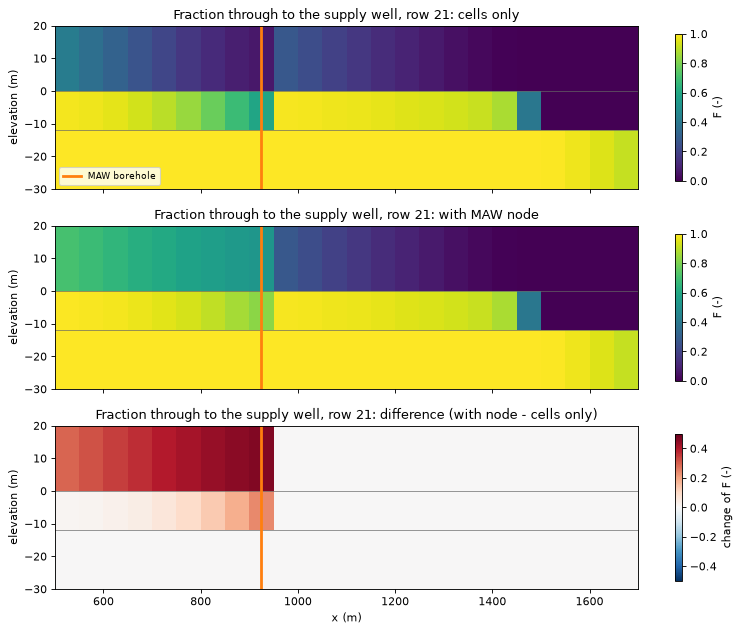

In [14]:
spec = maw.spec
z_edges = [spec.top, *hbd.LAYER_BOTM]
shape = (len(hbd.LAYER_BOTM), spec.nrow, spec.ncol)
F_maw_off = back_maw_off.fraction_through[WELL].reshape(shape)
F_maw_on = back_maw.fraction_through[WELL][: np.prod(shape)].reshape(shape)
row, col = maw.info["maw_cell"]
print("F in the MAW's cells, layers 1-3: cells only", F_maw_off[:, row, col].round(3),
      "| with MAW node", F_maw_on[:, row, col].round(3))
print(f"largest change of F anywhere: {np.abs(F_maw_on - F_maw_off).max():.3f}; cells whose F rises by more than 0.1: "
      f"{int(((F_maw_on - F_maw_off) > 0.1).sum())}")

panels = (
    (F_maw_off, "cells only", {"cmap": "viridis", "vmin": 0.0, "vmax": 1.0}, "F (-)"),
    (F_maw_on, "with MAW node", {"cmap": "viridis", "vmin": 0.0, "vmax": 1.0}, "F (-)"),
    (F_maw_on - F_maw_off, "difference (with node - cells only)", {"cmap": "RdBu_r", "vmin": -0.5, "vmax": 0.5},
     "change of F (-)"),
)
fig, axes = plt.subplots(3, 1, figsize=(10.0, 8.0), sharex=True)
for ax, (F, title, style, label) in zip(axes, panels):
    helpers.cross_section(ax, F, row, z_edges, spec.delr, label=label, **style)
    x_maw = (col + 0.5) * spec.delr
    ax.plot([x_maw, x_maw], [z_edges[-1], z_edges[0]], color="tab:orange", lw=2.5, label="MAW borehole")
    ax.set_title(f"Fraction through to the supply well, row {row + 1}: {title}")  # rows counted from 1
    ax.set_xlim(500.0, 1700.0)
for ax in axes[:-1]:
    ax.set_xlabel("")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

Without the node, the borehole is a sink in layers 1 and 2, so the water it takes there looks lost: only 6 % of the water in the MAW's layer-1 cell reaches the supply well. With the node, that rises to 53 %. The change reaches up-gradient through layer 1 west of the borehole, whose water flows towards it, and is smaller in the aquitard. Layer 3 is unchanged, because the MAW's inflow there was already traced to the well. The MAW pumps only 10 m³/d, less than half of the water that flows through its borehole. A long-screened well that pumps little can short-circuit an aquitard in this way. Water from a shallow aquifer, with whatever it carries, can then reach a deep supply aquifer.

## 5. A split model gives the same answer

Large models are sometimes split into several GWF models joined by **GWF-GWF exchanges**, for parallel runs or different grids. `gwsource` reads all models of a simulation into one global graph: the cells of every model, numbered model by model, with each exchange flow as an edge between the two cells it joins.

To show that nothing is lost, we split the quickstart model of tutorial 01 into three models with FloPy's `Mf6Splitter` (through `hbd.split_model`, which also switches on `SAVE_FLOWS` in every exchange). The west half becomes one model, and the east half becomes a north-east and a south-east quarter. The supply well and the river cross into different models.

In [15]:
single = hbd.build_quickstart(WORK / "single", MF6)
spec = single.spec
labels = np.zeros((spec.nrow, spec.ncol), dtype=int)  # one model number per cell
labels[:SPLIT_ROW, SPLIT_COL:] = 1
labels[SPLIT_ROW:, SPLIT_COL:] = 2
splitter = hbd.split_model(single, labels, WORK / "split", MF6)

exchange_file = sorted((WORK / "split").glob("*.gwfgwf"))[0]
options = exchange_file.read_text(encoding="utf-8").split("END options")[0]
print(exchange_file.name)
print("\n".join(line for line in options.splitlines() if line.strip() and not line.startswith("#")))

sim_quickstart_0_quickstart_1.gwfgwf
BEGIN options
  auxiliary  ANGLDEGX  CDIST
  SAVE_FLOWS


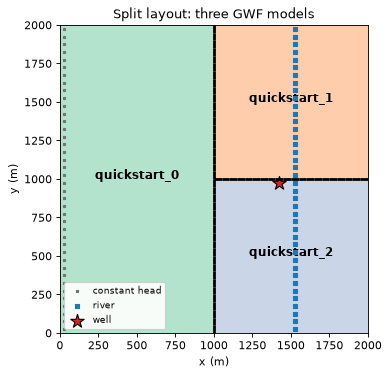

In [16]:
single_step = gs.read_step(single.ws, boundnames=True)
ax = hbd.plot_cells(single.grb_file, single_step, labels.ravel().astype(float), cmap="Pastel2", vmin=0, vmax=7,
                    title="Split layout: three GWF models", colorbar=False)
helpers.model_boundaries(ax, labels, spec.delr, spec.delc)
for number, (x, y) in enumerate(((500.0, 1000.0), (1500.0, 1500.0), (1500.0, 500.0))):
    ax.text(x, y, f"quickstart_{number}", ha="center", fontsize=11, weight="bold")
plt.show()

`gs.open_simulation` (or `gs.read_network` for one step) reads every GWF model listed in `mfsim.nam`. It checks that every exchange between two models it reads has `SAVE_FLOWS`, since the exchange flows are in the budget files only then. Term names get a `<model>/` prefix. Selectors match with or without it, so `boundnames=[WELL]` and `package="RCH"` work across models.

In [17]:
split = gs.read_network(WORK / "split", boundnames=True)
for block in split.blocks:
    print(f"{block.label}: nodes {block.offset}..{block.offset + block.n - 1}, grid {block.grid_shape}")
print("terms:", ", ".join(split.package_names))
print("exchanges read as edges:", ", ".join(split.notes["exchanges"]))

back_single = gs.backward(single_step, {WELL: gs.select(single_step, boundnames=[WELL])})
back_split = gs.backward(split, {WELL: gs.select(split, boundnames=[WELL])})

rows = {}
for output in ("fraction_through", "volume_through", "volume_from"):
    reference = getattr(back_single, output)[WELL]
    mapped = hbd.map_back(splitter, split, getattr(back_split, output)[WELL])  # to the original cells
    largest = np.abs(mapped - reference).max()
    rows[output] = {"max |split - single|": largest, "max |single|": np.abs(reference).max(),
                    "relative": largest / np.abs(reference).max()}
display(pd.DataFrame(rows).T)
F_split = hbd.map_back(splitter, split, back_split.fraction_through[WELL])
assert np.abs(F_split - back_single.fraction_through[WELL]).max() < 1e-8

quickstart_0: nodes 0..799, grid (1, 40, 20)
quickstart_1: nodes 800..1199, grid (1, 20, 20)
quickstart_2: nodes 1200..1599, grid (1, 20, 20)
terms: quickstart_0/RCH, quickstart_0/CHD, quickstart_1/RIV, quickstart_1/RCH, quickstart_2/WEL, quickstart_2/RIV, quickstart_2/RCH
exchanges read as edges: GWF-GWF_1, GWF-GWF_2, GWF-GWF_3


,max |split - single|,max |single|,relative
fraction_through,2.070566e-13,1.000000,2.070566e-13
volume_through,2.682299e-12,800.000000,3.352874e-15
volume_from,1.364242e-12,51.351804,2.656658e-14


`hbd.map_back` uses the splitter's node map to put each model's values back on the original grid. The largest difference in $F$ is $2 \times 10^{-13}$. MF6 solves the split simulation as a different linear system. Its heads and flows are therefore not bit-for-bit those of the single model, although both are solved to the same tolerance. The fractions of the two simulations agree to about $10^{-13}$. The other outputs agree to $3 \times 10^{-14}$ or better, relative to their largest value. The test suite checks every output, forward and backward, including travel times, on DIS, DISV and transient splits.

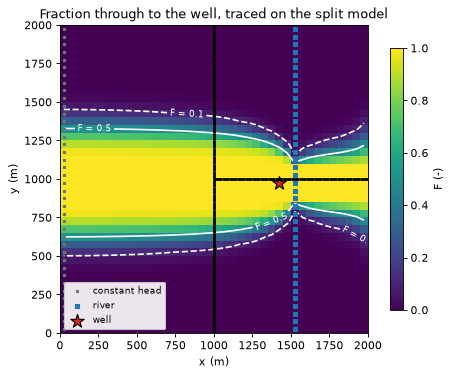

,volume_from,share
source,,
quickstart_0/RCH,329.7,0.412
quickstart_2/RCH,131.9,0.165
quickstart_0/CHD,118.1,0.148
quickstart_1/RCH,107.0,0.134
quickstart_2/RIV,81.7,0.102
quickstart_1/RIV,31.6,0.039


In [18]:
ax = hbd.plot_cells(single.grb_file, single_step, F_split, cmap="viridis", vmin=0.0, vmax=1.0,
                    title="Fraction through to the well, traced on the split model", label="F (-)")
hbd.add_contours(ax, single.grb_file, single_step, F_split, (0.1, 0.5), colors="w", linestyles=["--", "-"])
helpers.model_boundaries(ax, labels, spec.delr, spec.delc)
plt.show()
display(hbd.volume_from_table(back_split, WELL).round({"volume_from": 1, "share": 3}))

The capture zone crosses two model boundaries without a seam, and it matches tutorial 01. Because the source terms keep their model prefix, the volume-from table also splits the well's water **by model**. The well in the south-east model takes most of its recharge from the west model, and its river water from both eastern models.

### One model on its own

Read alone with `gs.read_step(ws, model=...)`, a model of the split simulation treats its exchanges as boundary terms (`GWF-GWF`), the same way the cells-only trace treated the stream. Water that crossed from a neighbouring model has no history:

In [19]:
alone = gs.read_step(WORK / "split", model="quickstart_2", boundnames=True)
back_alone = gs.backward(alone, {WELL: gs.select(alone, boundnames=[WELL])})
display(hbd.volume_from_table(back_alone, WELL).round({"volume_from": 1, "share": 3}))

,volume_from,share
source,,
GWF-GWF_3,344.5,0.431
GWF-GWF_2,241.9,0.302
RCH,131.9,0.165
RIV,81.7,0.102


In [20]:
print(f"notebook runtime: {time.perf_counter() - T_START:.0f} s")

notebook runtime: 3 s


## 6. What MODFLOW 6 must save, and current limits

| To trace through | MF6 option | If it is missing |
|---|---|---|
| any model (as in every tutorial) | `SAVE_FLOWS` on NPF and every package; OC `BUDGET SAVE`; the `.grb` file | – |
| GWF-GWF exchanges | `SAVE_FLOWS` in the exchange `OPTIONS` | `open_simulation` stops with an error naming the exchange file |
| SFR, LAK, MAW or UZF nodes | `BUDGET FILEOUT` in the package `OPTIONS` | `open_simulation(package_nodes=...)` stops with an error |
| MVR transfers (in a model with package nodes) | `BUDGET FILEOUT` in the MVR `OPTIONS` | `open_simulation` stops with an error |

Package nodes are optional: without `package_nodes`, `open_simulation` gives the cells-only results of section 2 exactly.

Current limitations:

- **Movers between models** (the simulation-level MVE package) are not read. Movers inside one model are.
- A mover transfer becomes an edge only if the receiving package has nodes and the provider's `TO-MVR` record is in the graph. Otherwise it stays a sink on the provider and a source on the receiver, as in section 2.
- Package nodes take their water volume (for travel times and transient tracking) from the `VOLUME` of the package's `STORAGE` record. Flux outputs (per unit area) are not defined on package nodes (NaN).
- Tested on MF6 models: SFR + MVR, MAW across layers, LAK with outlets, UZF with rejected infiltration moved to a lake, and splits of DIS, DISV and transient models. Covered only by hand-built tests: multi-layer UZF cell-to-cell flow, MAW flowing wells, and LAK or MAW as mover providers.
- The MF6 PRT particle helper of tutorial 06 works on single-model steps without package nodes only.
- Per-model output: `gs.result_view` / `gs.model_view` cut a network result down to one model's cells for the single-model exports. `gs.export.save_network` writes one npz per model, a CSV of the package nodes and a GeoPackage with a point layer for them.

## Key points

- Water that leaves the cells and comes back (through a stream, a mover, a well bore or another model) breaks a cells-only trace into an opaque sink and an opaque source.
- `gs.open_simulation(ws, package_nodes=(...))` adds one node per SFR reach, lake, MAW well or UZF cell, turns the package exchange records and MVR transfers into edges, and reads every GWF model of the simulation with exchanges as edges. Everything downstream (backward, forward, metrics, diagnostics, travel time, transient tracking) works on the larger graph unchanged.
- Stream and mover: with SFR nodes, the drained area joined the well's catchment, and the "SFR" source split into upstream inflow and recharge that travelled drain → mover → stream → aquifer.
- MAW: the borehole is a fully mixed node, so a weakly pumped well screened across an aquitard shows up as a short circuit that feeds the deeper supply well.
- A split simulation gives the single model's fractions to about $10^{-13}$. Read alone, a model's exchanges are boundary terms.
- These features need `SAVE_FLOWS` on the exchanges and `BUDGET FILEOUT` on the advanced packages and MVR.

## Next

[08 · Transient tracking](../08_transient_tracking/08_transient_tracking.ipynb): carry tagged water through storage from step to step, forward and backward, and compare with MF6 GWT.